# Fighter career statistics: exploratory plots

This notebook loads the fighter-level career statistics, visualizes correlations among all numeric predictors, and plots the distributions of the offensive predictors.

## Load data and set up analysis

In [95]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path("../data_clean/fighter_career_stats.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data_clean/fighter_career_stats.csv")

fighter_stats = pd.read_csv(DATA_PATH)

## Frequency Table for # of Fights

C:\Users\Abtin\AppData\Local\Temp\ipykernel_5460\3140771175.py:82: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


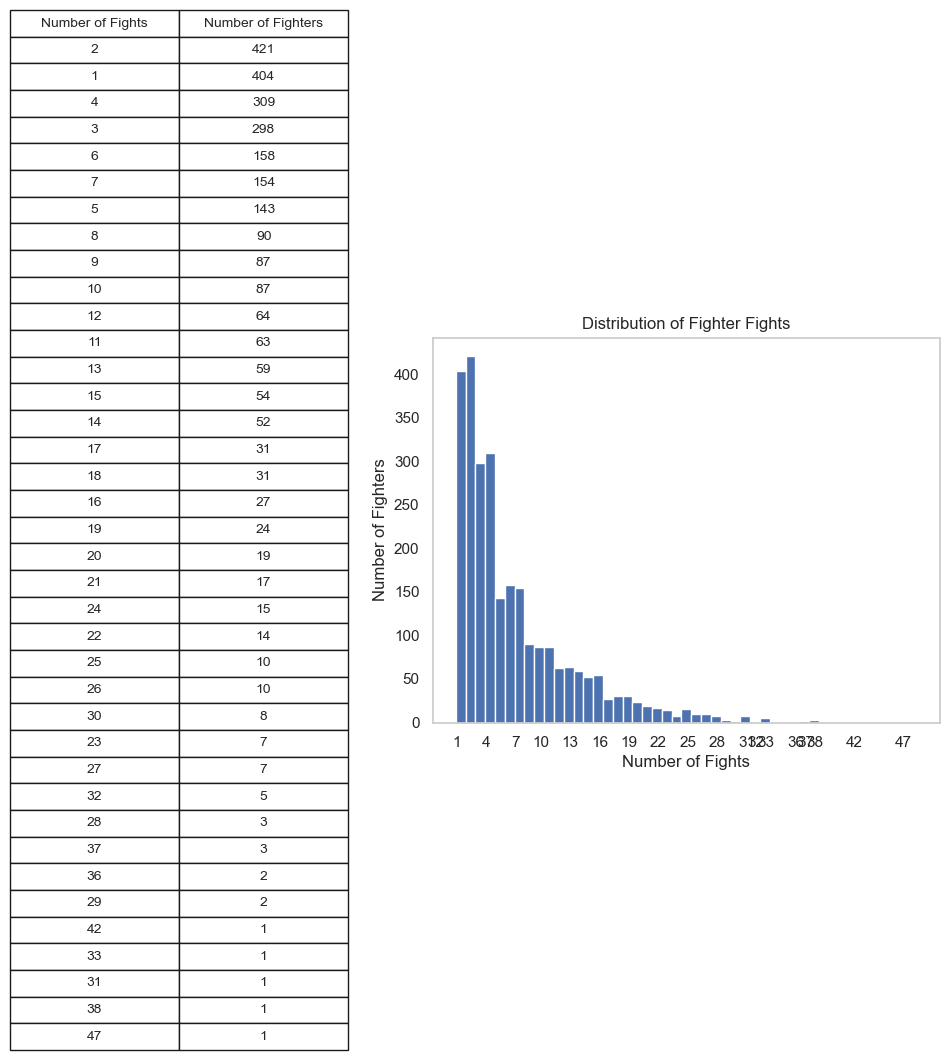

In [96]:
import numpy as np
import matplotlib.pyplot as plt

fight_counts = (
    fighter_stats["total_fights"]
    .value_counts()
    .reset_index()
    .sort_values(by="count", ascending=False)
)

fight_counts.columns = ["Number of Fights", "Number of Fighters"]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

# Table
axes[0].axis("off")

table = axes[0].table(
    cellText=fight_counts.values,
    colLabels=fight_counts.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

# Histogram
bins = np.arange(
    fighter_stats["total_fights"].min() - 0.5,
    fighter_stats["total_fights"].max() + 1.5,
    1
)

axes[1].hist(
    fighter_stats["total_fights"],
    bins=bins,
)

axes[1].set_title("Distribution of Fighter Fights")
axes[1].set_xlabel("Number of Fights")
axes[1].set_ylabel("Number of Fighters")

# Tick marks every 3 fights up to 30
max_fights = int(fighter_stats["total_fights"].max())

ticks_to_30 = np.arange(
    1,
    min(max_fights, 30) + 1,
    3
)

# After 30, show ticks only where fighters exist
ticks_after_30 = (
    fight_counts.loc[
        fight_counts["Number of Fights"] > 30,
        "Number of Fights"
    ]
    .to_numpy()
)

tick_values = np.concatenate([
    ticks_to_30,
    ticks_after_30
])

axes[1].set_xticks(tick_values)
axes[1].set_xticklabels(
    tick_values,
    ha="right"
)

# Remove histogram gridlines
axes[1].grid(False)

plt.tight_layout()
plt.show()

## Check missing values

In [97]:
# Identify missing values before performing exploratory analysis.
missing_mask = fighter_stats.isna()
missing_summary = (
    missing_mask.sum()
    .loc[lambda counts: counts.gt(0)]
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)
missing_summary["missing_pct"] = (
    100 * missing_summary["missing_count"] / len(fighter_stats)
)

missing_observations = fighter_stats.loc[missing_mask.any(axis=1)].copy()
missing_observations["missing_columns"] = missing_mask.loc[
    missing_observations.index
].apply(lambda row: ", ".join(row.index[row]), axis=1)

print(f"Observations with at least one missing value: {len(missing_observations):,}")
display(missing_summary)
display(missing_observations[["fighter", "missing_columns"]])

Observations with at least one missing value: 232


,missing_count,missing_pct
TD_def,232,8.647037


,fighter,missing_columns
3,Aalon Cruz,TD_def
6,Aaron Pico,TD_def
11,Abdul Rakhman Yakhyaev,TD_def
14,Abdul-Kerim Edilov,TD_def
16,Abner Lloveras,TD_def
...,...,...
2646,Yoshinori Horie,TD_def
2655,Yuri Villefort,TD_def
2664,Zach Light,TD_def
2667,Zachary Scroggin,TD_def


## Apply minimum fight filter

The notebook will be using min_total_fights = 2

In [98]:
MIN_TOTAL_FIGHTS = 2


filtered_fighter_stats = fighter_stats.loc[
    fighter_stats["total_fights"].ge(3)
].copy()
filtered_continuous_stats = (
    filtered_fighter_stats.select_dtypes(include="number")
    .replace([np.inf, -np.inf], np.nan)
    .dropna(axis=1, how="all")
)

print(
    f"Retained {len(filtered_fighter_stats):,} of {len(fighter_stats):,} fighters "
    f"with total_fights >= {3}."
)


filtered_fighter_stats = fighter_stats.loc[
    fighter_stats["total_fights"].ge(MIN_TOTAL_FIGHTS)
].copy()
filtered_continuous_stats = (
    filtered_fighter_stats.select_dtypes(include="number")
    .replace([np.inf, -np.inf], np.nan)
    .dropna(axis=1, how="all")
)

print(
    f"Retained {len(filtered_fighter_stats):,} of {len(fighter_stats):,} fighters "
    f"with total_fights >= {MIN_TOTAL_FIGHTS}."
)

Retained 1,858 of 2,683 fighters with total_fights >= 3.
Retained 2,279 of 2,683 fighters with total_fights >= 2.


## Check missing values after minimum fight filter

In [99]:
# 3. Check missing values after minimum fight filter.
filtered_missing_mask = filtered_fighter_stats.isna()
filtered_missing_summary = (
    filtered_missing_mask.sum()
    .loc[lambda counts: counts.gt(0)]
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)
filtered_missing_summary["missing_pct"] = (
    100 * filtered_missing_summary["missing_count"] / len(filtered_fighter_stats)
)

filtered_missing_observations = filtered_fighter_stats.loc[
    filtered_missing_mask.any(axis=1)
].copy()
filtered_missing_observations["missing_columns"] = filtered_missing_mask.loc[
    filtered_missing_observations.index
].apply(lambda row: ", ".join(row.index[row]), axis=1)

print(
    f"Observations with at least one missing value after filtering: "
    f"{len(filtered_missing_observations):,}"
)
display(filtered_missing_summary)
display(filtered_missing_observations[["fighter", "missing_columns"]])

Observations with at least one missing value after filtering: 84


,missing_count,missing_pct
TD_def,84,3.685827


,fighter,missing_columns
3,Aalon Cruz,TD_def
6,Aaron Pico,TD_def
11,Abdul Rakhman Yakhyaev,TD_def
78,Alex Reyes,TD_def
81,Alex Soto,TD_def
...,...,...
2562,Victor Rodriguez,TD_def
2564,Victor Valimaki,TD_def
2630,Yanis Ghemmouri,TD_def
2633,Yaroslav Amosov,TD_def


Minimum fight filtering is not the end way to get rid of missing values. 
Many fighters during their stint in the UFC have never fought an opponent who have attempted to take them down.

Ex. Mark Kerr, undefeated UFC run 4-0, Heavyweight champion at the time. During his UFC run he had never been taken down, however, not a single opponent even attempted a takedown against Mark Kerr. 

This begs the question, is TD_def an indicator of fighting style if it is dependent on the Oponent? 

## Correlations among continuous predictors

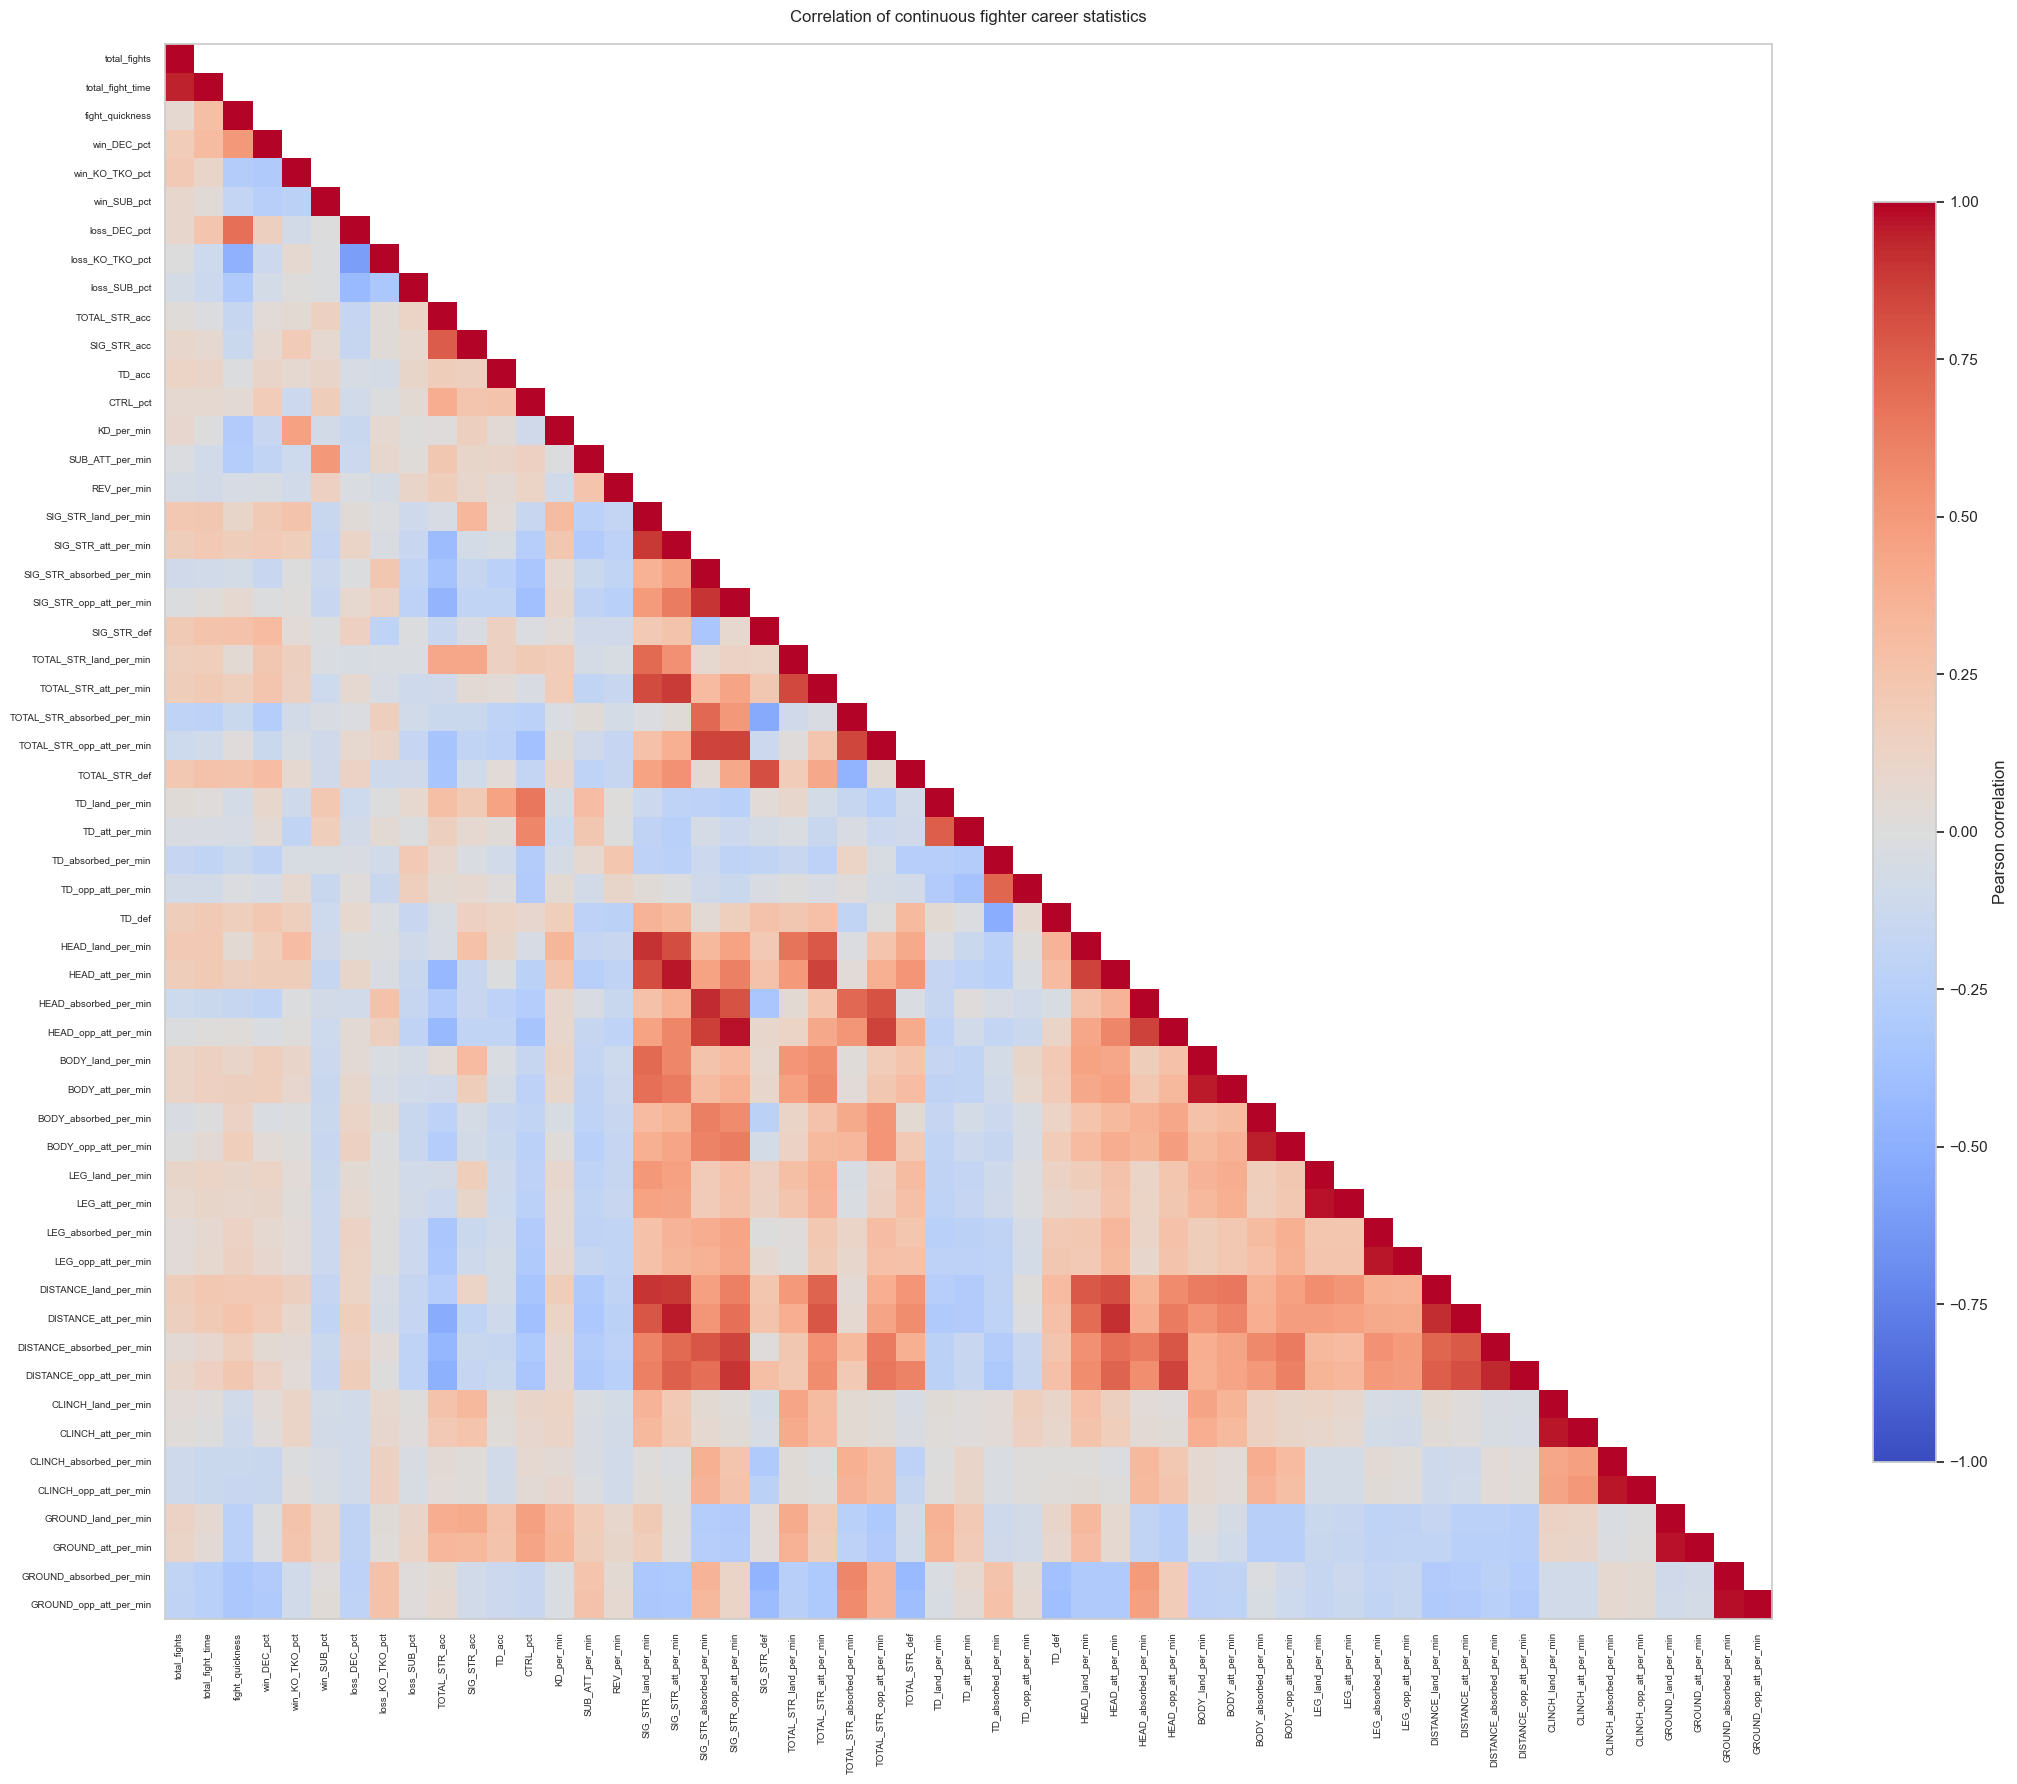

In [100]:
# Use the minimum-fight filtered dataset for all remaining analysis.
continuous_stats = filtered_continuous_stats.copy()
correlations = continuous_stats.corr()
upper_triangle = np.triu(np.ones_like(correlations, dtype=bool), k=1)

masked_correlations = correlations.mask(upper_triangle)
heatmap_cmap = plt.get_cmap("coolwarm").copy()
heatmap_cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(22, 18))
image = ax.imshow(
    masked_correlations,
    cmap=heatmap_cmap,
    vmin=-1,
    vmax=1,
    aspect="auto",
)
ax.set_xticks(np.arange(len(correlations.columns)))
ax.set_yticks(np.arange(len(correlations.index)))
ax.set_xticklabels(correlations.columns, rotation=90, fontsize=7)
ax.set_yticklabels(correlations.index, fontsize=7)
ax.minorticks_off()
ax.grid(False, which="both", axis="both")
ax.set_title("Correlation of continuous fighter career statistics", pad=16)
fig.colorbar(image, ax=ax, label="Pearson correlation", shrink=0.8)
plt.tight_layout()
plt.show()

### Top 10 most strongly correlated variable pairs

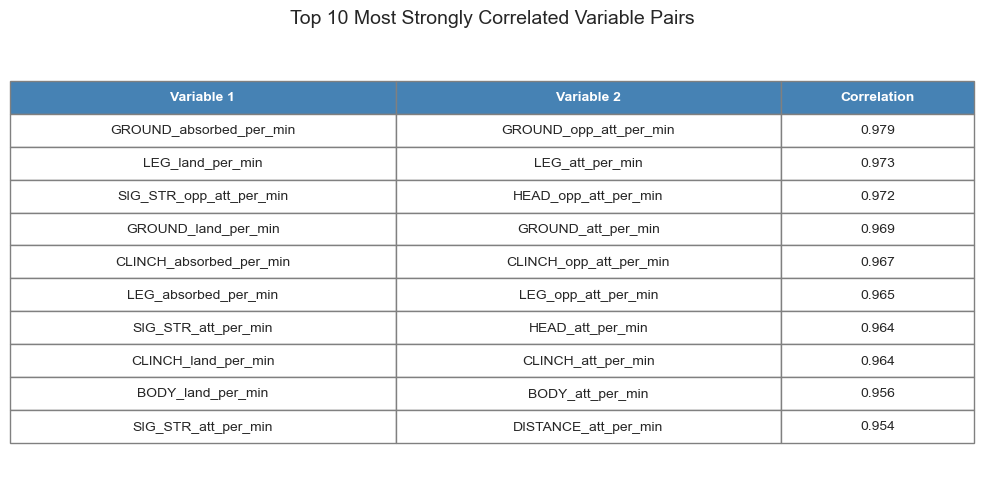

In [101]:
# Use the correlation matrix created above
upper_triangle = correlations.where(
    np.triu(np.ones(correlations.shape), k=1).astype(bool)
)

top_10_correlations = (
    upper_triangle
    .stack()
    .reset_index()
    .rename(columns={
        "level_0": "Variable 1",
        "level_1": "Variable 2",
        0: "Correlation"
    })
)

# Rank by absolute strength, but do not display absolute correlation
top_10_correlations = (
    top_10_correlations
    .assign(
        _sort_value=lambda df: df["Correlation"].abs()
    )
    .sort_values("_sort_value", ascending=False)
    .drop(columns="_sort_value")
    .head(10)
    .reset_index(drop=True)
)

# Format correlation values
table_data = top_10_correlations.copy()
table_data["Correlation"] = table_data["Correlation"].map(
    lambda x: f"{x:.3f}"
)

# Plot the table
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis("off")

correlation_table = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.40, 0.40, 0.20]
)

correlation_table.auto_set_font_size(False)
correlation_table.set_fontsize(10)
correlation_table.scale(1, 1.8)

# Style table cells
for (row, column), cell in correlation_table.get_celld().items():
    cell.set_edgecolor("gray")

    if row == 0:
        cell.set_facecolor("steelblue")
        cell.set_text_props(color="white", weight="bold")

plt.title(
    "Top 10 Most Strongly Correlated Variable Pairs",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()


While it is intuitive that offensive varaibles, like attempted and landed are going to be highly correlated, I wanted to observed how oppoenent stats relate to a fighter's offensive output. 

The idea of including opp stats is that a fighter who fights a certain style will often force their opponent to fight that same style. For example a high action brawler will often force the action resulting in a high output fight. Or a clinch fighter will force the opponent into a clinch. etc. Over time, the avg opp stats should even out to give an extra idea of how a fighter fights.

Now we observe the correlation between offensive stats against opponent stats.

### Offense vs Opoonent Stat Correlation

In [109]:
offensive_predictors = [
    "SIG_STR_att_per_min",
    "TOTAL_STR_att_per_min",
    "HEAD_att_per_min",
    "BODY_att_per_min",
    "LEG_att_per_min",
    "DISTANCE_att_per_min",
    "CLINCH_att_per_min",
    "GROUND_att_per_min",
    "TD_att_per_min",
    "SUB_ATT_per_min",
]

opponent_predictors = [
    "SIG_STR_opp_att_per_min",
    "TOTAL_STR_opp_att_per_min",
    "HEAD_opp_att_per_min",
    "BODY_opp_att_per_min",
    "LEG_opp_att_per_min",
    "DISTANCE_opp_att_per_min",
    "CLINCH_opp_att_per_min",
    "GROUND_opp_att_per_min",
    "TD_opp_att_per_min",
]

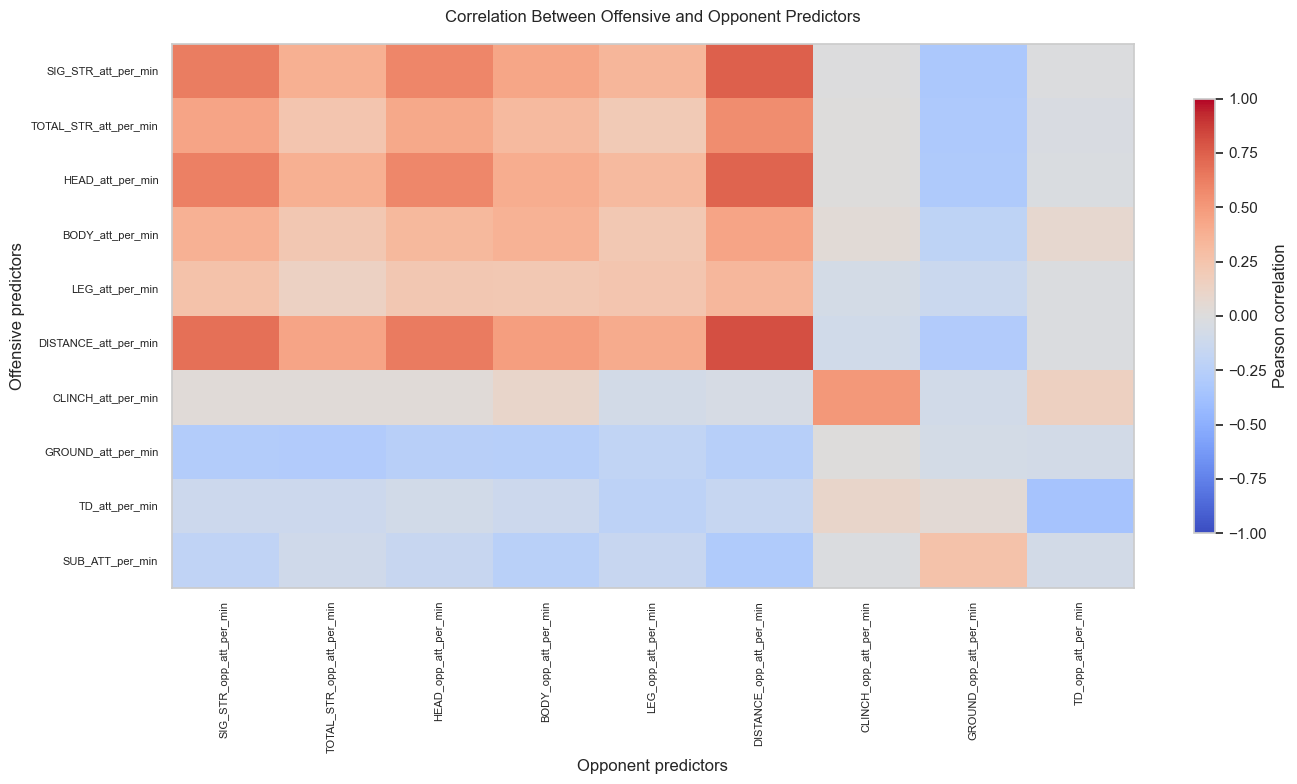

In [111]:
# plot offensive vs opponent corrplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



# Use the minimum-fight filtered dataset
continuous_stats = filtered_continuous_stats.copy()

# Calculate offensive-versus-defensive correlations
cross_correlations = pd.DataFrame(
    [
        [
            continuous_stats[offensive].corr(continuous_stats[defensive])
            for defensive in opponent_predictors
        ]
        for offensive in offensive_predictors
    ],
    index=offensive_predictors,
    columns=opponent_predictors
)

# Create the correlation plot
heatmap_cmap = plt.get_cmap("coolwarm").copy()
heatmap_cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(14, 8))

image = ax.imshow(
    cross_correlations,
    cmap=heatmap_cmap,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(np.arange(len(opponent_predictors)))
ax.set_yticks(np.arange(len(offensive_predictors)))

ax.set_xticklabels(
    opponent_predictors,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    offensive_predictors,
    fontsize=8
)

ax.minorticks_off()
ax.grid(False, which="both", axis="both")

ax.set_xlabel("Opponent predictors")
ax.set_ylabel("Offensive predictors")
ax.set_title(
    "Correlation Between Offensive and Opponent Predictors",
    pad=16
)

fig.colorbar(
    image,
    ax=ax,
    label="Pearson correlation",
    shrink=0.8
)

plt.tight_layout()
plt.show()

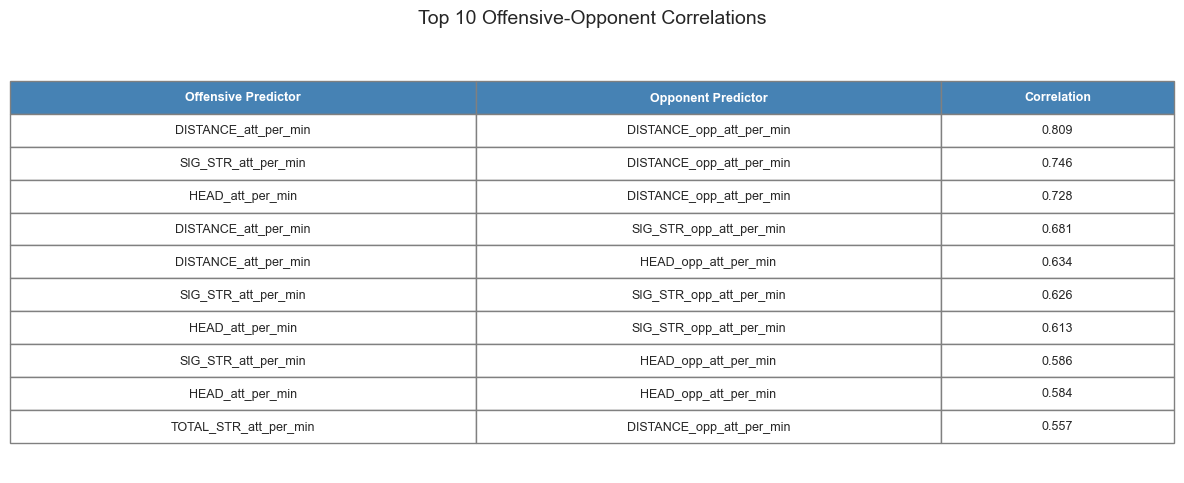

In [112]:
# Find the strongest offensive-versus-defensive correlations
top_10_correlations = (
    cross_correlations
    .stack()
    .rename("Correlation")
    .reset_index()
)

top_10_correlations.columns = [
    "Offensive Predictor",
    "Opponent Predictor",
    "Correlation"
]

# Rank by absolute strength without displaying absolute correlation
top_10_correlations = (
    top_10_correlations
    .assign(
        _sort_value=lambda df: df["Correlation"].abs()
    )
    .sort_values("_sort_value", ascending=False)
    .drop(columns="_sort_value")
    .head(10)
    .reset_index(drop=True)
)

# Format values for display
table_data = top_10_correlations.copy()
table_data["Correlation"] = table_data["Correlation"].map(
    lambda value: f"{value:.3f}"
)

# Plot the table
fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")

correlation_table = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.40, 0.40, 0.20]
)

correlation_table.auto_set_font_size(False)
correlation_table.set_fontsize(9)
correlation_table.scale(1, 1.8)

# Style table cells
for (row, column), cell in correlation_table.get_celld().items():
    cell.set_edgecolor("gray")

    if row == 0:
        cell.set_facecolor("steelblue")
        cell.set_text_props(color="white", weight="bold")

plt.title(
    "Top 10 Offensive-Opponent Correlations",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()

## Offensive density plots

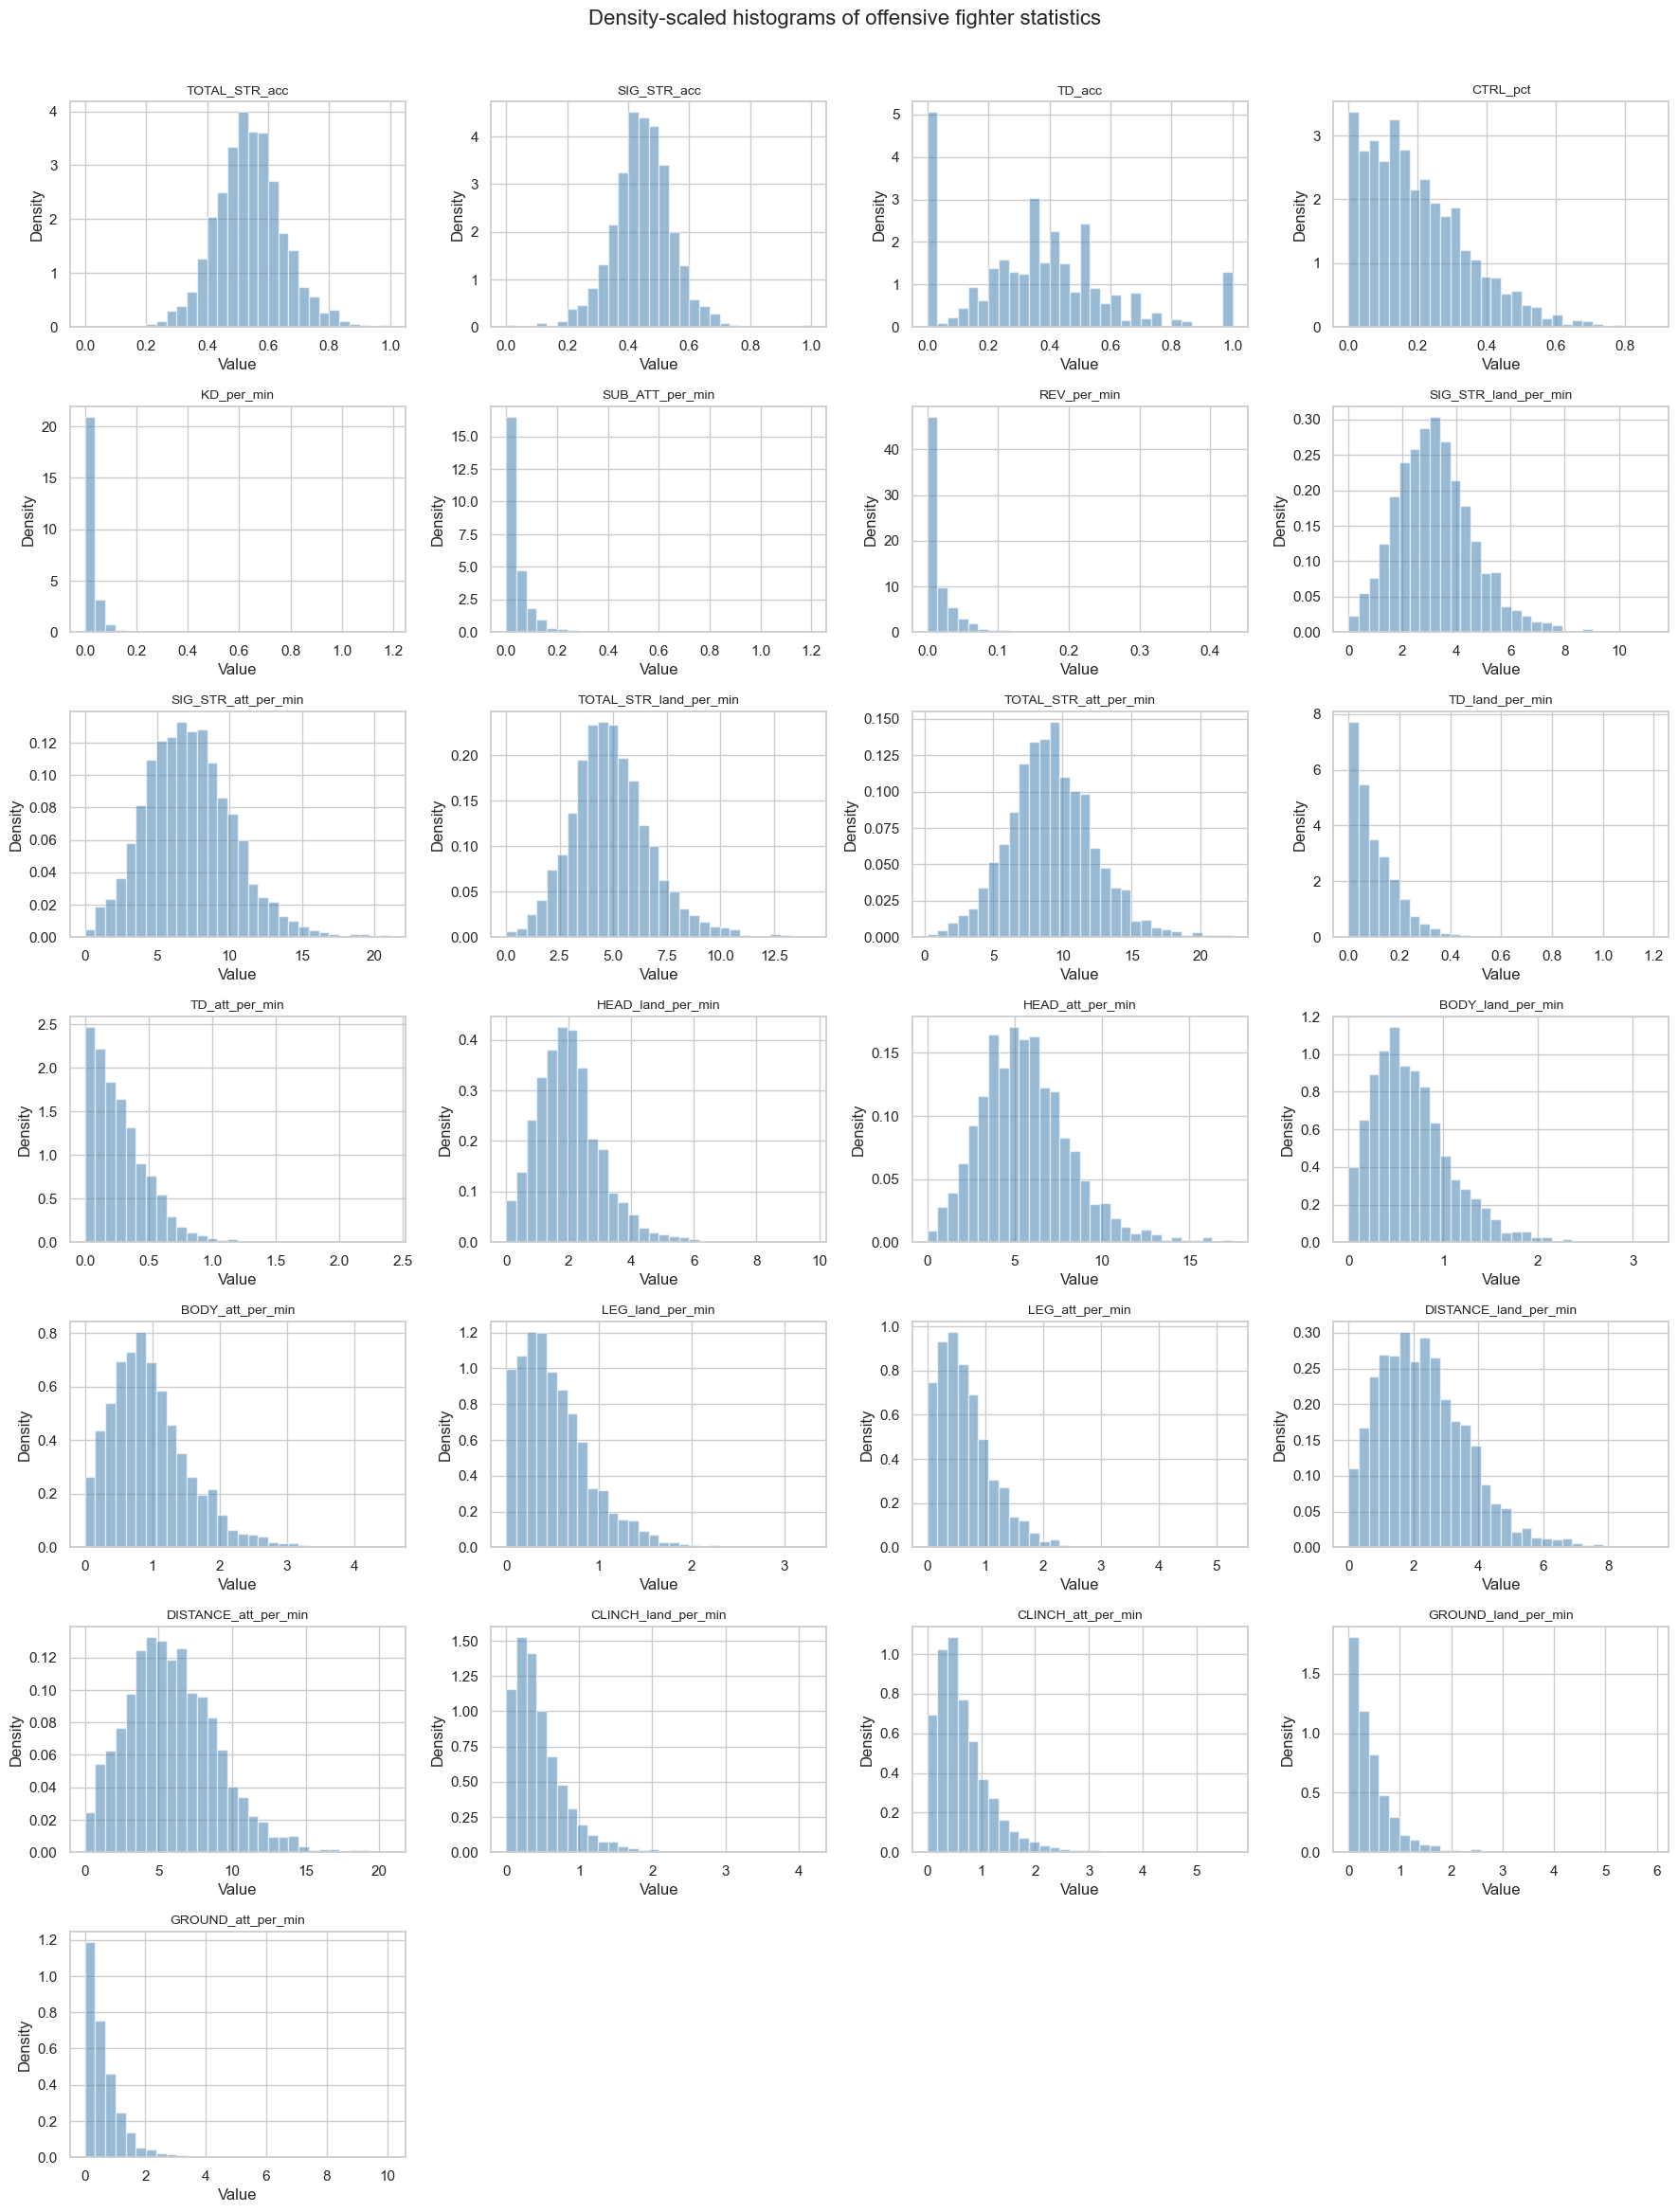

In [102]:
offensive_summary_columns = {
    "TOTAL_STR_acc",
    "SIG_STR_acc",
    "TD_acc",
    "CTRL_pct",
    "KD_per_min",
    "SUB_ATT_per_min",
    "REV_per_min",
}

offensive_columns = [
    column
    for column in continuous_stats.columns
    if (
        column in offensive_summary_columns
        or column.endswith(("_land_per_min", "_att_per_min"))
    )
    and "_opp_" not in column
    and "_absorbed_" not in column
]

n_columns = 4
n_rows = int(np.ceil(len(offensive_columns) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(18, 3.3 * n_rows))
axes = np.asarray(axes).ravel()

for ax, column in zip(axes, offensive_columns):
    values = continuous_stats[column].dropna()
    if values.nunique() > 1:
        ax.hist(
            values,
            bins=30,
            density=True,
            color="steelblue",
            alpha=0.55,
            edgecolor="white",
        )
    elif not values.empty:
        ax.axvline(values.iloc[0], linewidth=2)
    ax.set_title(column, fontsize=10)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

for ax in axes[len(offensive_columns):]:
    ax.remove()

fig.suptitle("Density-scaled histograms of offensive fighter statistics", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## Variables with the highest share of zero values

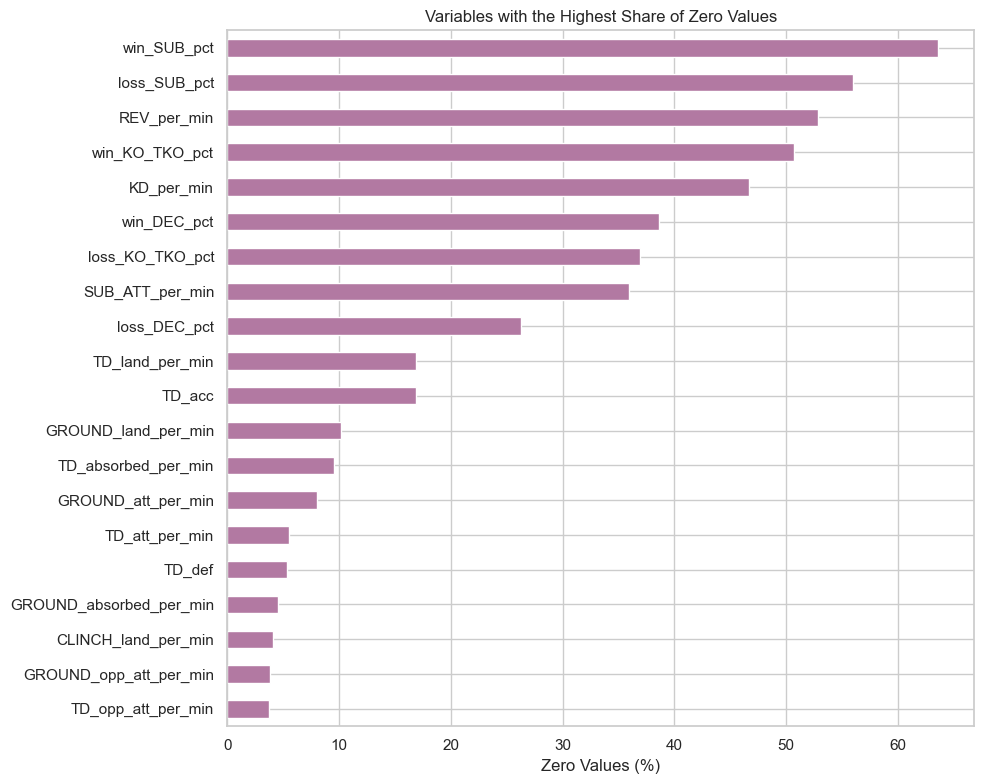

In [103]:
# 7. Variables with the highest share of zero values
# Use the filtered numerical variables from the notebook
features = continuous_stats.copy()

# Calculate the percentage of zero values for each variable
zero_rate = (
    features.eq(0)
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Create a summary table
zero_summary = pd.DataFrame({
    "zero_pct": zero_rate,
    "missing_cells": features.isna().sum(),
    "median": features.median()
}).sort_values(
    "zero_pct",
    ascending=False
)
# Plot the 20 variables with the highest percentage of zero values
plot_zero_rate = zero_rate.head(20).sort_values()

fig, ax = plt.subplots(figsize=(10, 8))

plot_zero_rate.plot(
    kind="barh",
    ax=ax,
    color="#b279a2"
)

ax.set_title("Variables with the Highest Share of Zero Values")
ax.set_xlabel("Zero Values (%)")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

## Pairwise plots of offensive attempted rates

This matrix shows pairwise relationships among the offensive attempted-rate variables.

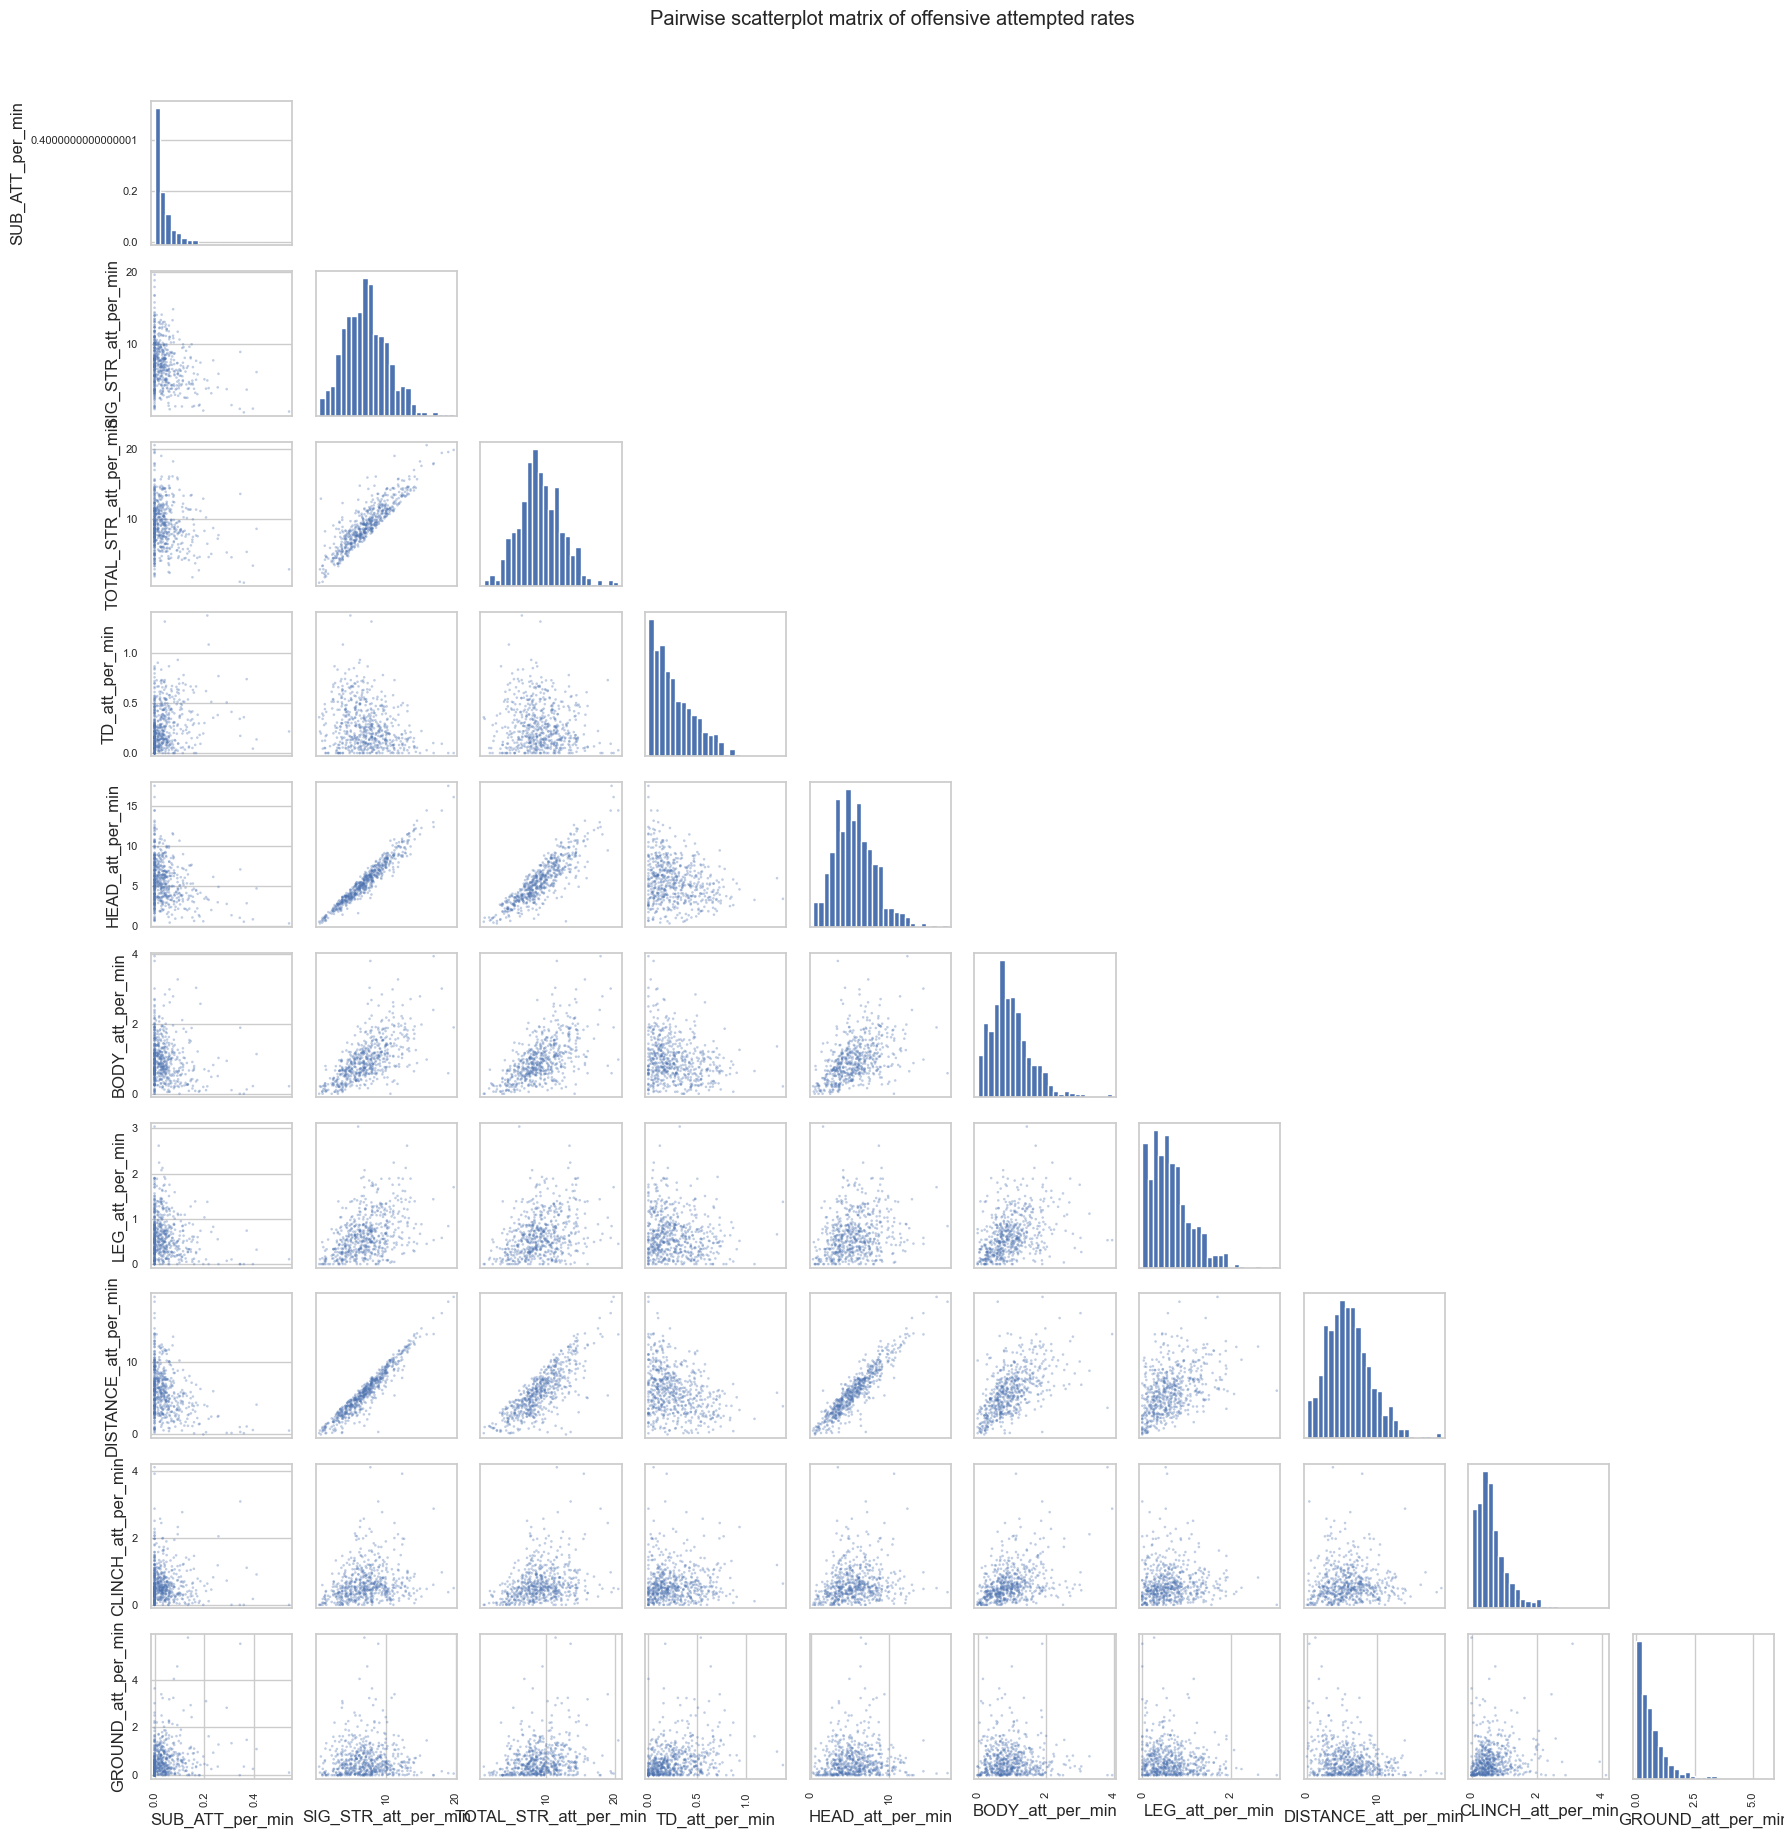

In [104]:
# 8. Pairwise plots of offensive attempted rates
# Limit the matrix to the attempted-rate metrics in the offensive histogram grid.
attempt_columns = [
    column for column in offensive_columns if column.lower().endswith("_att_per_min")
]

attempt_stats = continuous_stats[attempt_columns].dropna()
attempt_stats = attempt_stats.sample(
    n=min(600, len(attempt_stats)), random_state=42
)

def plot_scatter_matrix(data, title):
    axes = pd.plotting.scatter_matrix(
        data,
        alpha=0.35,
        s=14,
        diagonal="hist",
        hist_kwds={"bins": 25},
        figsize=(18, 18),
        edgecolors="none",
    )

    for row_index in range(axes.shape[0]):
        for column_index in range(axes.shape[1]):
            if column_index > row_index:
                axes[row_index, column_index].set_visible(False)

    figure = axes[0, 0].get_figure()
    figure.suptitle(title, y=1.02)
    figure.tight_layout()
    return figure

plot_scatter_matrix(
    attempt_stats,
    "Pairwise scatterplot matrix of offensive attempted rates",
)
plt.show()

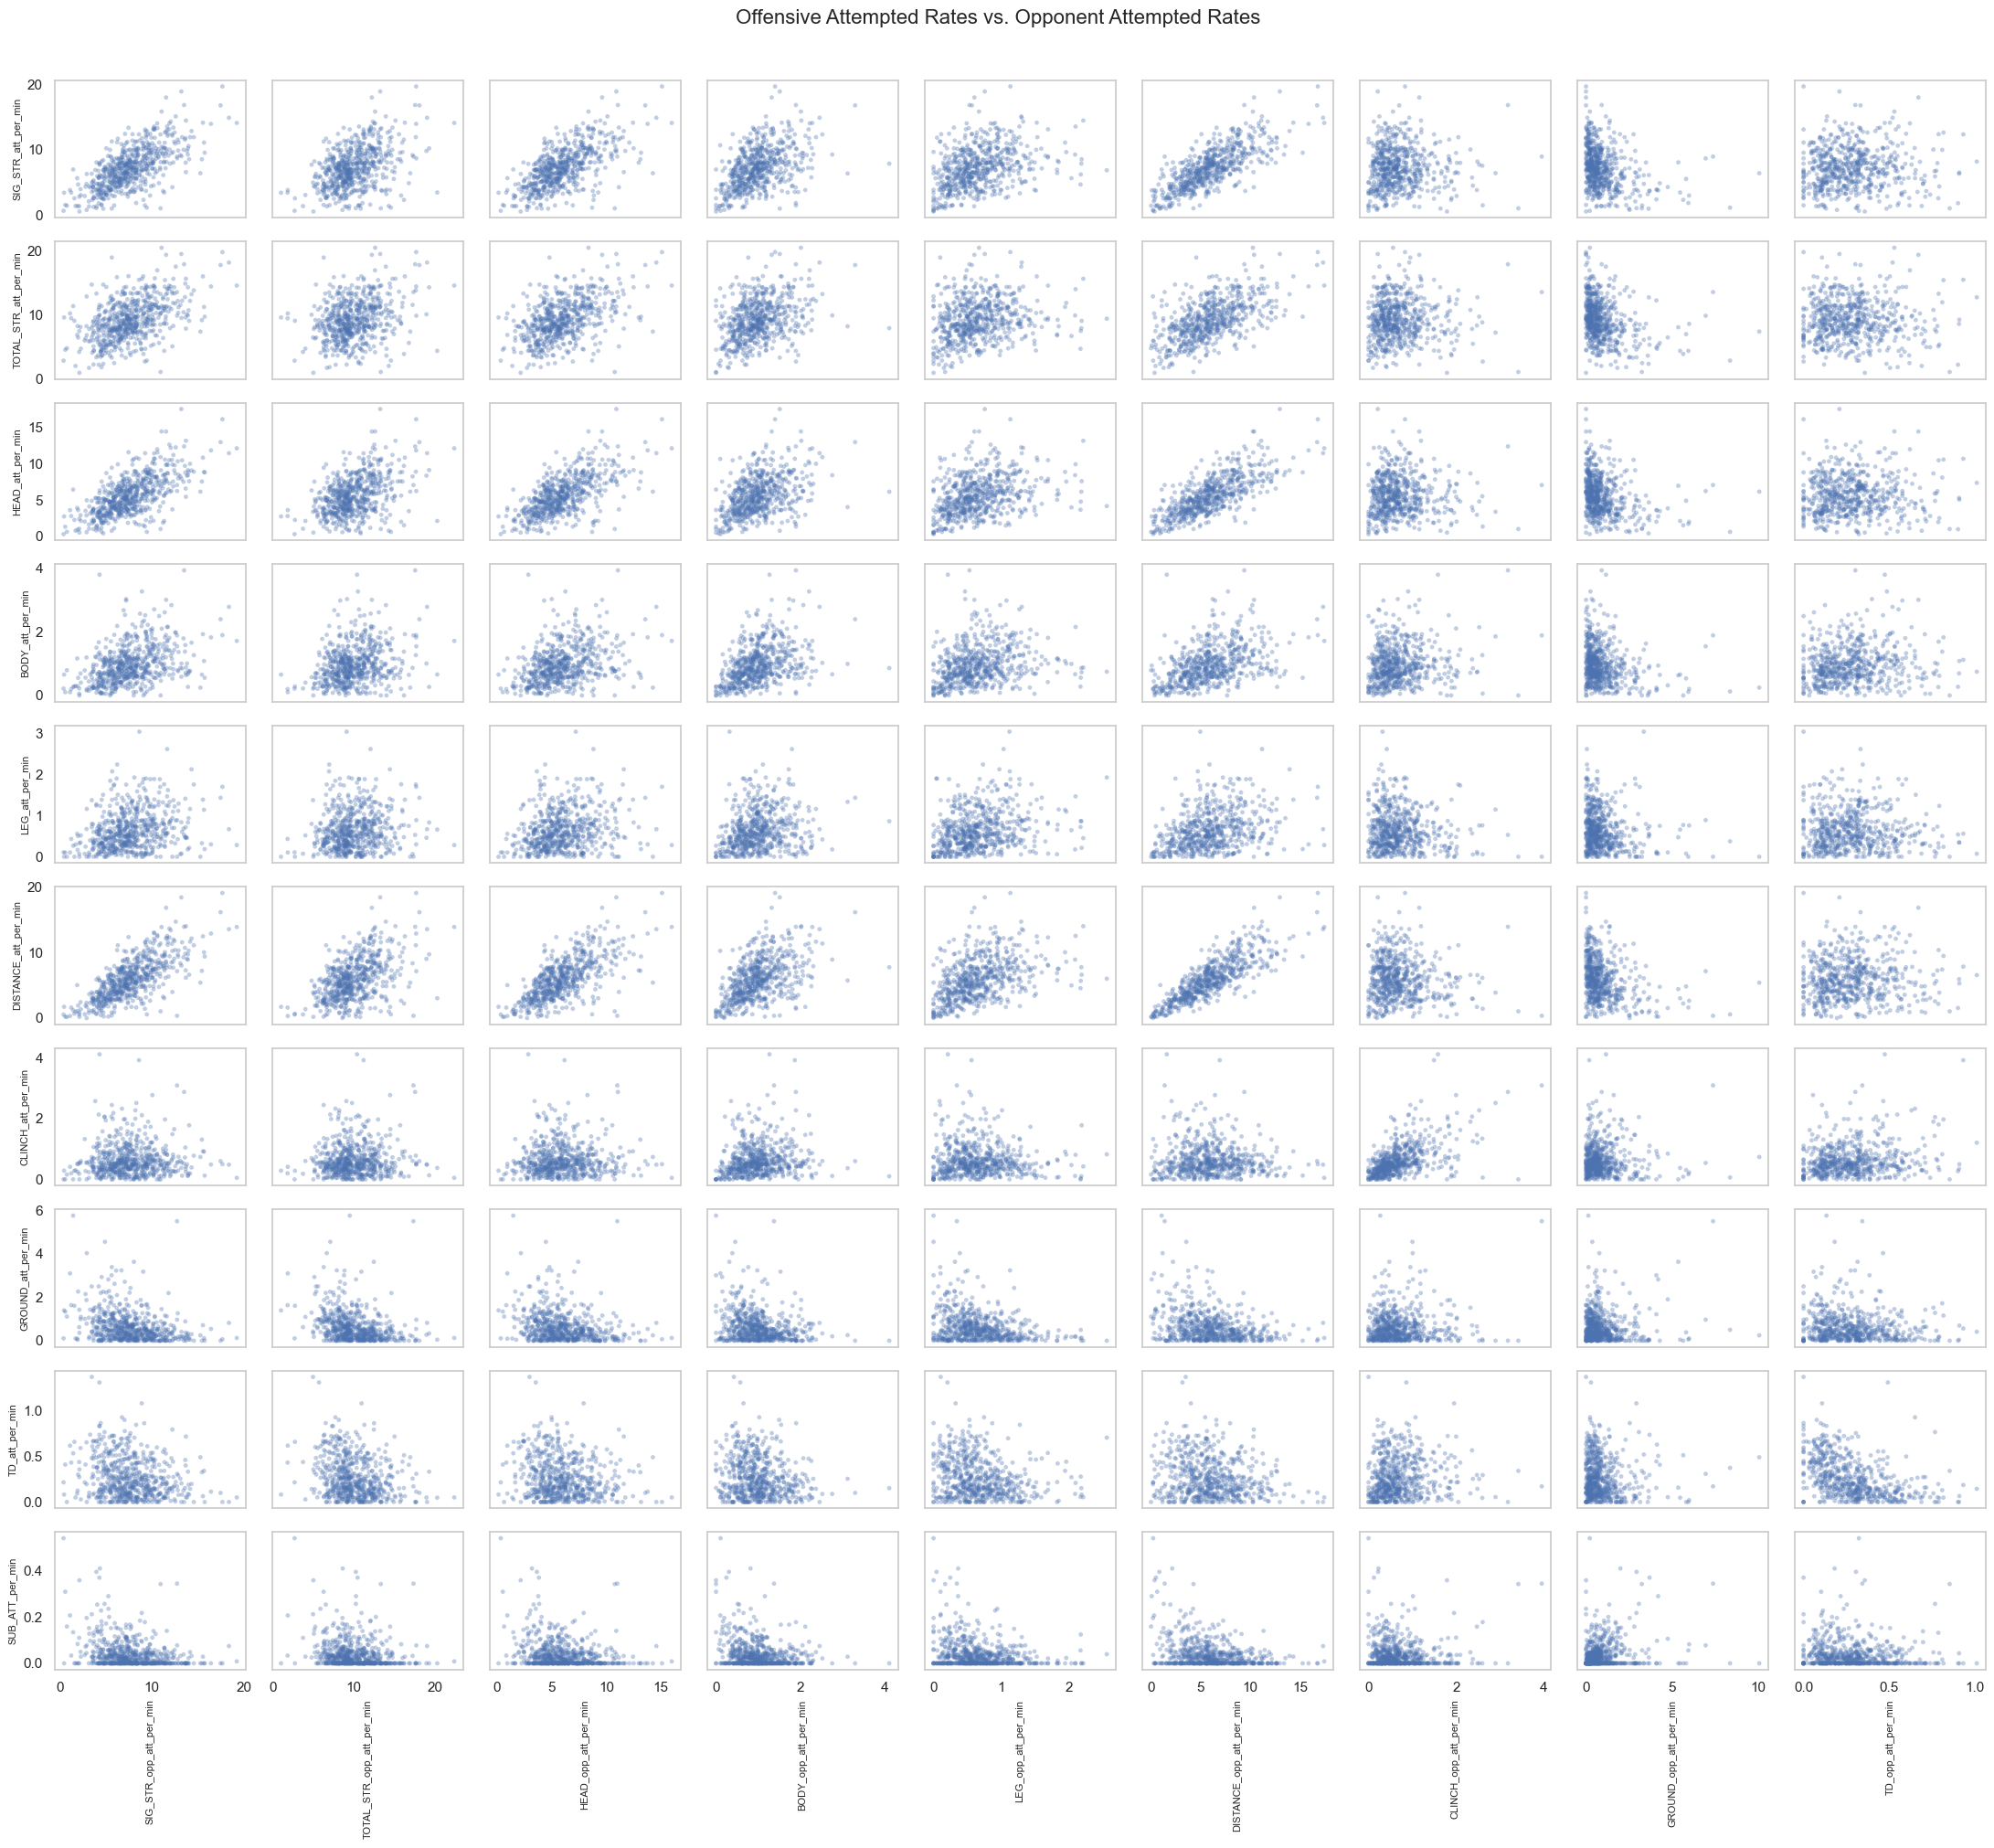

In [114]:
plot_data = (
    continuous_stats[offensive_predictors + opponent_predictors]
    .dropna()
    .sample(n=min(600, len(continuous_stats)), random_state=42)
)

fig, axes = plt.subplots(
    len(offensive_predictors),
    len(opponent_predictors),
    figsize=(22, 20),
    sharex="col",
    sharey="row"
)

for row, offensive in enumerate(offensive_predictors):
    for column, opponent in enumerate(opponent_predictors):
        ax = axes[row, column]

        ax.scatter(
            plot_data[opponent],
            plot_data[offensive],
            alpha=0.35,
            s=12,
            edgecolors="none"
        )

        ax.grid(False)

        if row == len(offensive_predictors) - 1:
            ax.set_xlabel(
                opponent,
                rotation=90,
                fontsize=8
            )
        else:
            ax.set_xlabel("")

        if column == 0:
            ax.set_ylabel(offensive, fontsize=8)
        else:
            ax.set_ylabel("")

plt.suptitle(
    "Offensive Attempted Rates vs. Opponent Attempted Rates",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

## 9. PCA scree plot

This section standardizes the filtered career-statistics variables and shows how much variation is explained by each principal component. `total_fights` is excluded because it measures exposure rather than fighting style.

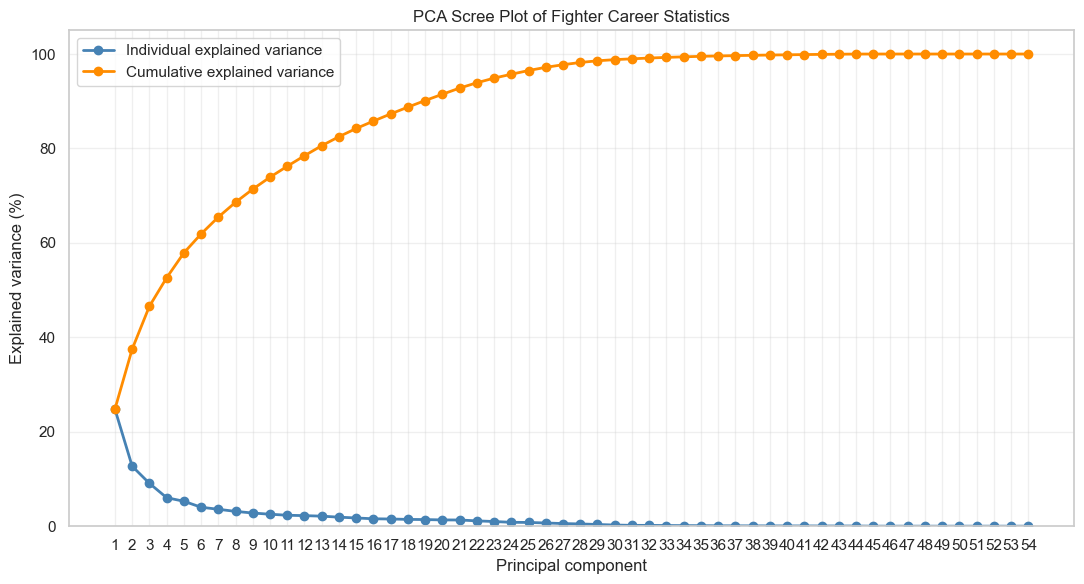

In [105]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Use the same minimum-fight filtered data as the later EDA sections.
pca_data = filtered_continuous_stats.drop(columns=['total_fights'], errors='ignore')
pca_data = pca_data.replace([np.inf, -np.inf], np.nan)

# Fill missing values before PCA so every fighter can be retained.
pca_imputed = SimpleImputer(strategy='mean').fit_transform(pca_data)

# Standardize variables because the career statistics use different scales.
pca_scaled = StandardScaler().fit_transform(pca_imputed)

pca = PCA()
pca.fit(pca_scaled)

component_numbers = np.arange(1, len(pca.explained_variance_ratio_) + 1)
explained_variance_pct = 100 * pca.explained_variance_ratio_
cumulative_variance_pct = np.cumsum(explained_variance_pct)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    component_numbers,
    explained_variance_pct,
    marker='o',
    linewidth=2,
    color='steelblue',
    label='Individual explained variance'
)
ax.plot(
    component_numbers,
    cumulative_variance_pct,
    marker='o',
    linewidth=2,
    color='darkorange',
    label='Cumulative explained variance'
)
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance (%)')
ax.set_title('PCA Scree Plot of Fighter Career Statistics')
ax.set_xticks(component_numbers)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [115]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# True = dimension-adjusted Hopkins
# False = standard unpowered Hopkins
DIMENSION_ADJUSTED = True


# Use only the selected predictors
hopkins_data = (
    continuous_stats
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Standardize predictors before calculating distances
hopkins_data = StandardScaler().fit_transform(hopkins_data)


def calculate_hopkins(data, sample_size=100, random_state=None):
    rng = np.random.default_rng(random_state)

    n_rows, n_columns = data.shape
    sample_size = min(sample_size, n_rows // 2)

    # Randomly sample real observations
    real_indices = rng.choice(
        n_rows,
        size=sample_size,
        replace=False
    )

    real_sample = data[real_indices]

    # Distances from real observations to their nearest other real observation
    real_neighbors = NearestNeighbors(n_neighbors=2)
    real_neighbors.fit(data)

    real_distances = real_neighbors.kneighbors(
        real_sample,
        return_distance=True
    )[0][:, 1]

    # Generate artificial observations uniformly across observed ranges
    lower_bounds = data.min(axis=0)
    upper_bounds = data.max(axis=0)

    artificial_sample = rng.uniform(
        lower_bounds,
        upper_bounds,
        size=(sample_size, n_columns)
    )

    # Distances from artificial observations to nearest real observations
    artificial_neighbors = NearestNeighbors(n_neighbors=1)
    artificial_neighbors.fit(data)

    artificial_distances = artificial_neighbors.kneighbors(
        artificial_sample,
        return_distance=True
    )[0][:, 0]

    # Apply dimension adjustment if selected
    if DIMENSION_ADJUSTED:
        p = n_columns
        artificial_values = artificial_distances ** p
        real_values = real_distances ** p
    else:
        artificial_values = artificial_distances
        real_values = real_distances

    return (
        artificial_values.sum()
        / (
            artificial_values.sum()
            + real_values.sum()
        )
    )


# Repeat the calculation to assess stability
hopkins_scores = []

for repetition in range(10):
    score = calculate_hopkins(
        hopkins_data,
        sample_size=2000,
        random_state=42 + repetition
    )

    hopkins_scores.append(score)

hopkins_results = pd.DataFrame({
    "Repetition": np.arange(1, len(hopkins_scores) + 1),
    "Hopkins Statistic": hopkins_scores
})

display(hopkins_results)

version_label = (
    "dimension-adjusted"
    if DIMENSION_ADJUSTED
    else "standard unpowered"
)

print(f"Hopkins version: {version_label}")
print(f"Mean Hopkins statistic: {np.mean(hopkins_scores):.3f}")
print(f"Standard deviation: {np.std(hopkins_scores):.3f}")
if DIMENSION_ADJUSTED:
    print(f"Number of dimensions used: {hopkins_data.shape[1]}")

,Repetition,Hopkins Statistic
0,1,0.998042
1,2,0.999812
2,3,0.998837
3,4,1.000000
4,5,0.999400
5,6,0.999654
6,7,0.999211
7,8,0.999323
8,9,1.000000
9,10,1.000000


Hopkins version: dimension-adjusted
Mean Hopkins statistic: 0.999
Standard deviation: 0.001
Number of dimensions used: 55


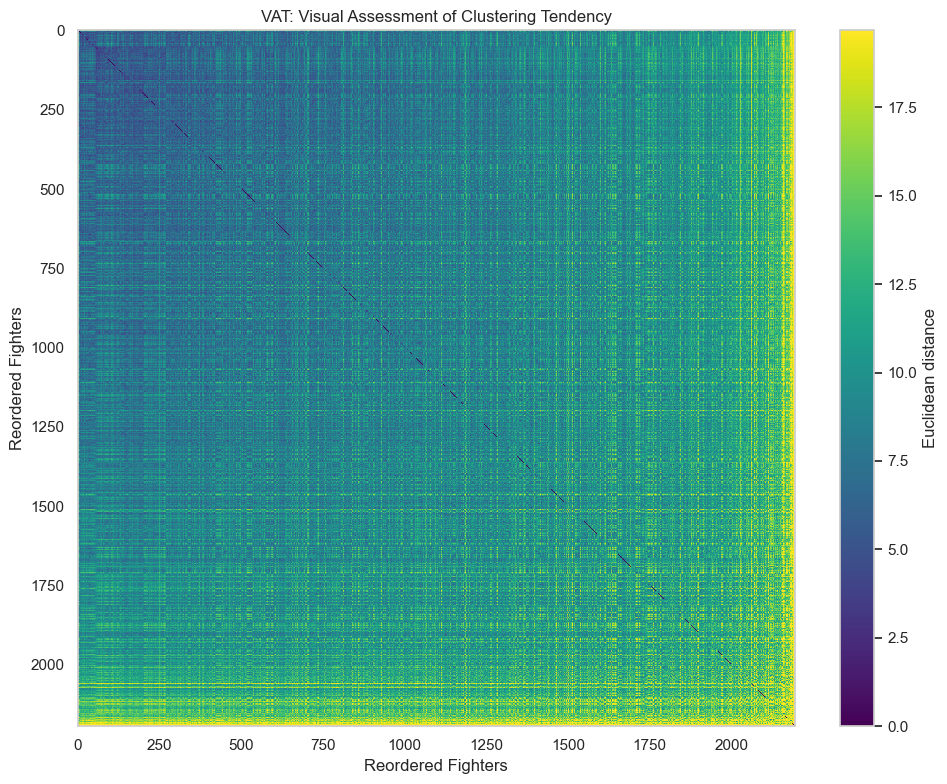

In [119]:
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler

# Use all selected predictors
vat_data = (
    continuous_stats
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Standardize predictors before calculating distances
vat_scaled = StandardScaler().fit_transform(vat_data)

# Calculate pairwise Euclidean distances
distance_matrix = squareform(
    pdist(vat_scaled, metric="euclidean")
)

# Reorder observations using the VAT ordering procedure
def vat_order(distances):
    n_observations = distances.shape[0]

    order = np.empty(n_observations, dtype=int)
    remaining = np.ones(n_observations, dtype=bool)

    # Start with the observation having the largest total distance
    first_index = np.unravel_index(
        np.argmax(distances), distances.shape
    )[0]
    order[0] = first_index
    remaining[first_index] = False

    # Track each remaining observation's distance to the selected set
    minimum_distances = distances[first_index].copy()
    minimum_distances[first_index] = np.inf

    for position in range(1, n_observations):
        next_index = np.argmin(
            np.where(remaining, minimum_distances, np.inf)
        )

        order[position] = next_index
        remaining[next_index] = False

        minimum_distances = np.minimum(
            minimum_distances,
            distances[next_index]
        )

    return order


vat_indices = vat_order(distance_matrix)

# Reorder the distance matrix
reordered_distances = distance_matrix[
    np.ix_(vat_indices, vat_indices)
]

# Plot the VAT heatmap
fig, ax = plt.subplots(figsize=(10, 8))


# Set color bar limits to 99th percentile, since 100 gives outlier
image = ax.imshow(
    reordered_distances,
    cmap="viridis",
    vmin=0,
    vmax=np.percentile(reordered_distances, 99),
    aspect="auto",
    interpolation="nearest"
)

ax.set_title("VAT: Visual Assessment of Clustering Tendency")
ax.set_xlabel("Reordered Fighters")
ax.set_ylabel("Reordered Fighters")
ax.grid(False)

fig.colorbar(
    image,
    ax=ax,
    label="Euclidean distance"
)

plt.tight_layout()
plt.show()